# Data Visualization — Quiz (Lectures 1–7)

**Time:** 90 minutes 
**Tools:** Plotly only (`plotly.express` first, then `update_traces` / `update_layout` / `update_xaxes` / `update_yaxes`)

**Your task:** answer each analytical question with **one polished, explanatory visualization**. For every question **you decide which chart type fits best** — and justify the choice in one or two sentences.

**Every figure must have:**
1. An **insight title** that states the finding, not just the variables
2. `template='plotly_white'` and a decluttered layout (no unnecessary gridlines, legends or axis titles)
3. A **CVD-safe palette** — no red/green; grey for context + one accent colour where it helps
4. Colour that **encodes meaning**, not decoration
5. Direct labels or annotations where they help the reader

**Chart types covered in the course** — choose from these:
line chart · sorted bar chart · stacked / 100% stacked bar chart · scatter plot · bubble chart · histogram · box plot · violin plot · choropleth map · treemap

> 💡 Each question has one chart type that fits it best, and the questions together cover most of the list above. If two of your answers use the same chart type, check the question again.


**Submit:** this notebook pushed to your personal repo as `quiz/dataviz_quiz.ipynb`

## The dataset — World Population 1970–2022

**Source:** [World Population Dataset](https://www.kaggle.com/datasets/iamsouravbanerjee/world-population-dataset) on Kaggle, compiled from Worldometer (UN World Population Prospects estimates). **234 rows × 16 columns — one row per country or territory, no missing values.**

| Column | Type | Description |
|---|---|---|
| `Country`, `Capital` | categorical | Country / territory and its capital |
| `Continent` | categorical | Africa, Asia, Europe, North America, Oceania, South America |
| `CCA3` | spatial | ISO-3 country code — use with `locationmode='ISO-3'` |
| `1970 Population` … `2022 Population` | temporal | Population in 1970, 1980, 1990, 2000, 2010, 2015, 2020, 2022 |
| `Area` | numerical | Land area in km² |
| `Density` | numerical | People per km² (2022) |
| `World share (%)` | numerical | Share of world population in 2022 |
| `Rank` | numerical | Rank by 2022 population |

**The next setup cell also gives you `df_long` — the same data in **tidy (long) format** with one row per country per year. Use `df` for one-year questions and `df_long` for questions about change over time**

In [2]:
import pandas as pd
import plotly.express as px
import numpy as np

df = pd.read_csv('world_population.csv')

# Shorter column names
df = df.rename(columns={'Country/Territory': 'Country', 'Area (km²)': 'Area',
                        'Density (per km²)': 'Density', 'World Population Percentage': 'World share (%)'})

# Tidy (long) version: one row per country per year
year_cols = [c for c in df.columns if c.endswith('Population')]
df_long = df.melt(id_vars=['CCA3', 'Country', 'Continent'], value_vars=year_cols,
                  var_name='Year', value_name='Population')

df_long['Year'] = df_long['Year'].str[:4].astype(int)     # '2022 Population' → 2022

print(df.shape, df_long.shape)


(234, 16) (1872, 5)


---
## Q1 — Which continent is growing fastest?

How has the population of each continent **grown since 1970, relative to its 1970 size** — and which continent is growing fastest?


**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.

*I chose a line chart to compare population growth across the six continents from 1970 to 2022. It makes it easy to see how population has changed over time. Africa has experienced the fastest growth, so I highlighted it with a different colour. The other continents are also shown in different colours to make the chart easier to read.*

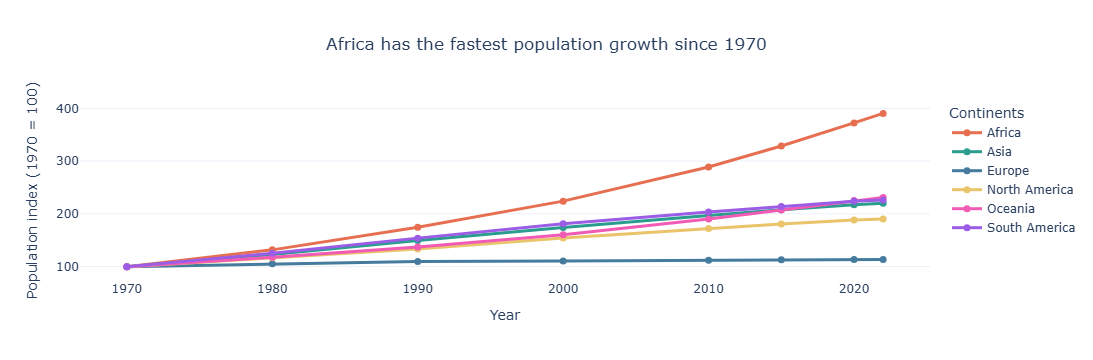

In [5]:

# Q1: Which continent is growing fastest?

# Calculate the total population for each continent and year
continent_pop = df_long.groupby(
    ['Continent', 'Year']
)['Population'].sum().reset_index()

# Calculate population growth compared to 1970
continent_pop['Index'] = continent_pop.groupby(
    'Continent'
)['Population'].transform(lambda x: x / x.iloc[0] * 100)

# Choose a different colour for each continent
colors = {
    'Africa': '#E76F51',
    'Asia': '#2A9D8F',
    'Europe': '#457B9D',
    'North America': '#E9C46A',
    'South America': '#9B5DE5',
    'Oceania': '#F15BB5'
}

# Create the line chart
fig = px.line(
    continent_pop,
    x='Year',
    y='Index',
    color='Continent',
    markers=True,
    color_discrete_map=colors,
    title='Africa has the fastest population growth since 1970',
    labels={
        'Year': 'Year',
        'Index': 'Population index (1970 = 100)',
        'Continent': 'Continent'
    }
)

# Improve the chart appearance
fig.update_layout(
    template='plotly_white',
    xaxis_showgrid=False,
    yaxis_showgrid=True,
    legend_title_text='Continents',
    title_x=0.5
)

fig.update_traces(line=dict(width=3), marker=dict(size=7))

fig.show()


---
## Q2 — Which countries added the most people?

Which **15 countries added the most people** between 1970 and 2022 — and how many of them are in **Africa**?

**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.

*India added the highest number of people between 1970 and 2022, with approximately 860 million people, followed by China with around 603 million. Out of the top 15 countries, 4 are in Africa: Nigeria, Ethiopia, DR Congo and Egypt. This shows that population growth has been especially strong in some Asian and African countries.*

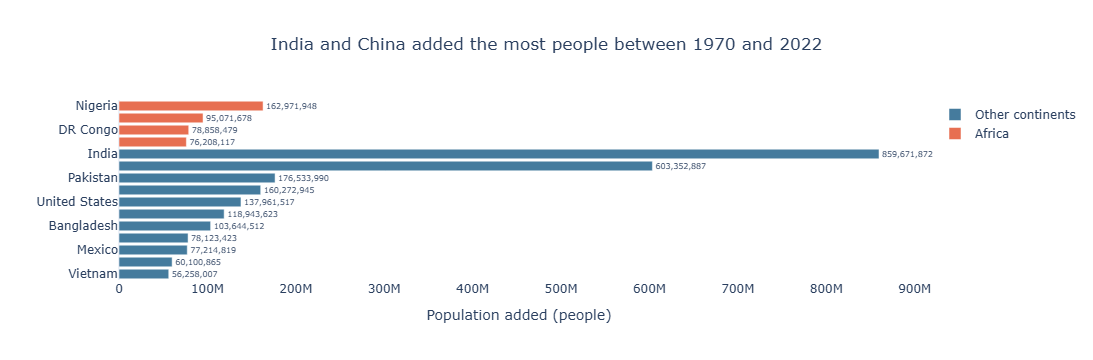

Number of African countries in the top 15: 4


In [6]:

# Q2: Which countries added the most people?

# Calculate how many people each country added
df['Population Added'] = (
    df['2022 Population'] - df['1970 Population']
)

# Select the 15 countries with the biggest increase
top15 = df.nlargest(15, 'Population Added').copy()

# Check which countries are in Africa
top15['Region'] = top15['Continent'].apply(
    lambda x: 'Africa' if x == 'Africa' else 'Other continents'
)

# Count the African countries
africa_count = (top15['Continent'] == 'Africa').sum()

# Arrange countries from smallest to largest increase
top15 = top15.sort_values(
    'Population Added', ascending=True
)

# Give African countries orange and others blue
colors = {
    'Africa': '#E76F51',
    'Other continents': '#457B9D'
}

# Create a horizontal bar chart
fig = px.bar(
    top15,
    x='Population Added',
    y='Country',
    orientation='h',
    color='Region',
    color_discrete_map=colors,
    title='India and China added the most people between 1970 and 2022',
    labels={
        'Population Added': 'Population added (people)',
        'Country': '',
        'Region': 'Region'
    },
    text='Population Added'
)

# Improve the chart design
fig.update_traces(
    texttemplate='%{text:,.0f}',
    textposition='outside',
    cliponaxis=False
)

fig.update_layout(
    template='plotly_white',
    title_x=0.5,
    xaxis_showgrid=False,
    yaxis_showgrid=False,
    legend_title_text=''
)

fig.show()

print("Number of African countries in the top 15:", africa_count)


---
## Q3 — Do bigger countries have more people?

Is there a relationship between a country's **land area** and its **2022 population** — does it differ by **continent**, and which countries clearly break the pattern?

**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.

*I chose a scatter plot because it helps show the relationship between the land area and population of different countries. I used different colours for each continent to make comparisons easier. I also used logarithmic scales because countries have very different land areas and population sizes.*

*The chart shows that larger countries often have larger populations, but this is not always true. India and Bangladesh have very large populations despite having smaller land areas. Russia has the largest land area but a much smaller population compared with India and China. This shows that a country's land area does not always determine its population.*

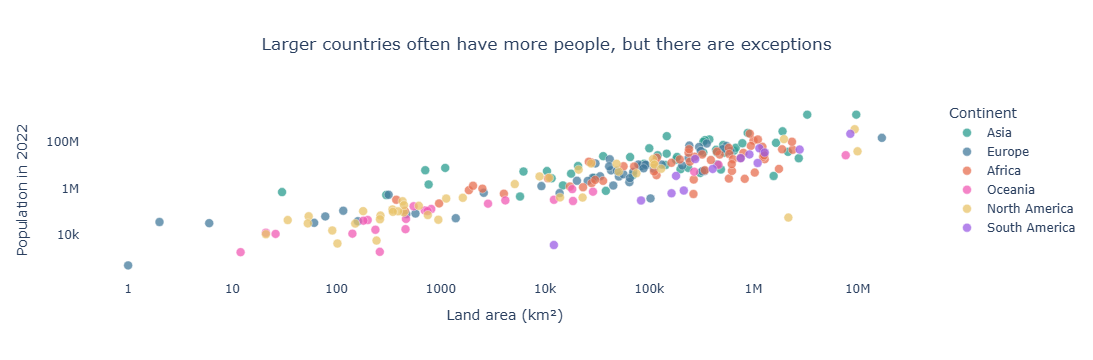

In [8]:

# Q3: Do bigger countries have more people?

# Compare the land area and population of countries
fig = px.scatter(
    df,
    x='Area',
    y='2022 Population',
    color='Continent',
    hover_name='Country',
    log_x=True,
    log_y=True,
    opacity=0.75,
    title='Larger countries often have more people, but there are exceptions',
    color_discrete_map={
        'Africa': '#E76F51',
        'Asia': '#2A9D8F',
        'Europe': '#457B9D',
        'North America': '#E9C46A',
        'South America': '#9B5DE5',
        'Oceania': '#F15BB5'
    },
    labels={
        'Area': 'Land area (km²)',
        '2022 Population': 'Population in 2022',
        'Continent': 'Continent'
    }
)

# Improve the chart design
fig.update_layout(
    template='plotly_white',
    title_x=0.5,
    xaxis_showgrid=False,
    yaxis_showgrid=False,
    legend_title_text='Continent'
)

fig.update_traces(
    marker=dict(size=9, line=dict(width=0.5, color='white'))
)

fig.show()


---
## Q4 — How crowded are the continents?

How does **population density vary within and across continents**? Show the spread, not just the average.

**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.

*I chose a violin plot because it shows how population density differs across continents. I used different colours to make each continent easy to identify and a logarithmic scale to show the differences more clearly.*

*The chart shows that Asia has many densely populated countries, such as India and Bangladesh. In contrast, Australia has a much lower population density because of its large land area. This shows that people are not equally spread around the world.*

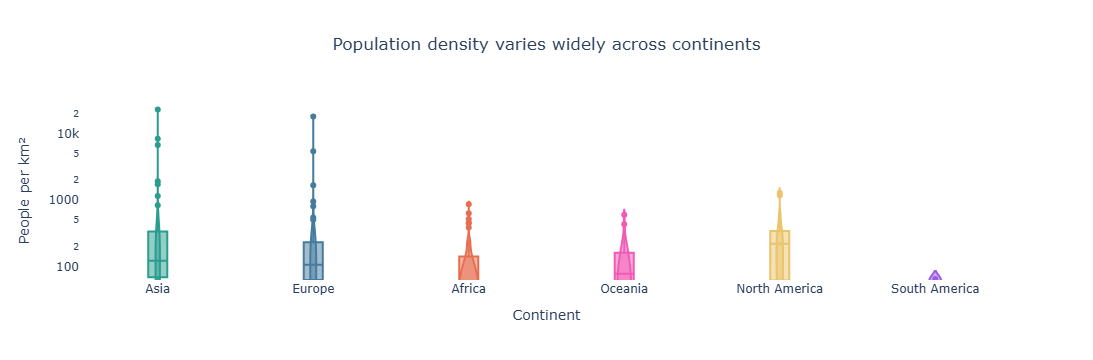

In [9]:
# Q4

# Q4: How crowded are the continents?

# Compare population density across continents
fig = px.violin(
    df,
    x='Continent',
    y='Density',
    color='Continent',
    box=True,
    points='outliers',
    log_y=True,
    title='Population density varies widely across continents',
    color_discrete_map={
        'Africa': '#E76F51',
        'Asia': '#2A9D8F',
        'Europe': '#457B9D',
        'North America': '#E9C46A',
        'South America': '#9B5DE5',
        'Oceania': '#F15BB5'
    },
    labels={
        'Continent': 'Continent',
        'Density': 'People per km²'
    }
)

# Improve the chart appearance
fig.update_layout(
    template='plotly_white',
    title_x=0.5,
    showlegend=False,
    xaxis_showgrid=False,
    yaxis_showgrid=False
)

fig.show()


---
## Q5 — Where did populations grow — and where did they shrink?

Which countries' populations **grew and which shrank between 2000 and 2022** (percentage change), and where in the world are they?

**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.

*I chose a choropleth map because it makes it easy to see population changes in different countries around the world. I used different colours to show which countries had population growth and which had a decline.*

*The map shows that most countries experienced population growth between 2000 and 2022. Countries like Qatar had a large increase, while countries like Ukraine experienced a population decline. This shows that population changes are different across the world.*

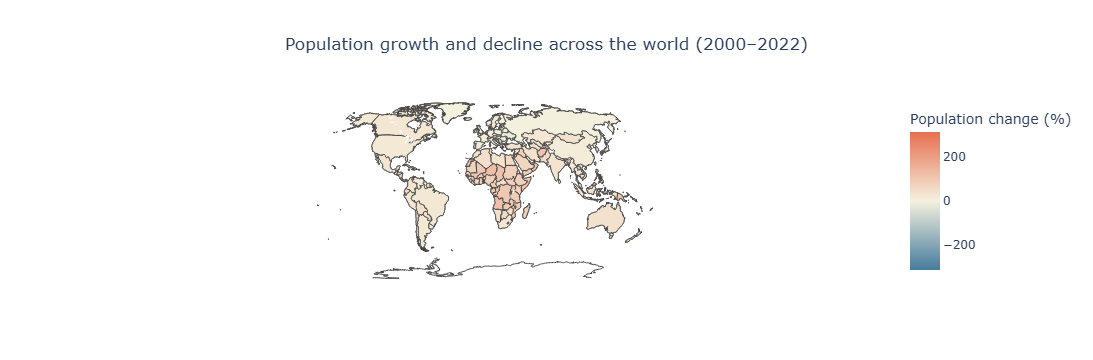

In [10]:

# Q5: Where did populations grow and where did they shrink?

# Calculate the percentage change in population
df['Population Change (%)'] = (
    (df['2022 Population'] - df['2000 Population'])
    / df['2000 Population']
) * 100

# Create a world map to show population changes
fig = px.choropleth(
    df,
    locations='CCA3',
    color='Population Change (%)',
    hover_name='Country',
    color_continuous_scale=[
        '#457B9D',
        '#F4F1DE',
        '#E76F51'
    ],
    color_continuous_midpoint=0,
    title='Population growth and decline across the world (2000–2022)',
    labels={
        'Population Change (%)': 'Population change (%)'
    },
    hover_data={
        'Population Change (%)': ':.1f'
    }
)

# Improve the map appearance
fig.update_layout(
    template='plotly_white',
    title_x=0.5,
    geo=dict(
        showframe=False,
        showcoastlines=True,
        projection_type='natural earth'
    )
)

fig.show()


---
## Q6 — Where do the world's 8 billion people live?

How is the **2022 world population** distributed across **continents and the countries within them**? Show both levels in one figure.

**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.

*I chose a treemap because it shows how the world's population is divided between continents and countries. The size of each box represents the population, and different colours make the continents easy to identify.*

*The chart shows that Asia has the largest population, followed by Africa. India and China have the biggest populations among the countries. This shows that most of the world's people live in Asia.*

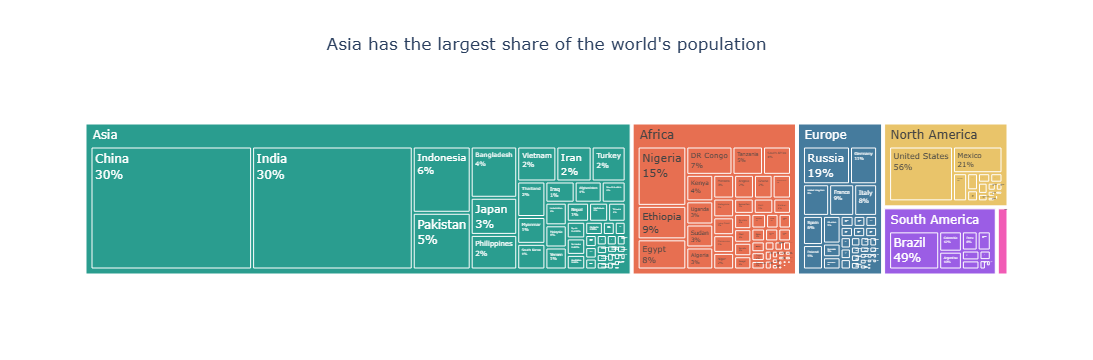

In [12]:

# Q6: Where do the world's 8 billion people live?

# Create a treemap to show population by continent and country
fig = px.treemap(
    df,
    path=['Continent', 'Country'],
    values='2022 Population',
    color='Continent',
    color_discrete_map={
        'Africa': '#E76F51',
        'Asia': '#2A9D8F',
        'Europe': '#457B9D',
        'North America': '#E9C46A',
        'South America': '#9B5DE5',
        'Oceania': '#F15BB5'
    },
    title="Asia has the largest share of the world's population",
    hover_data={
        '2022 Population': ':,'
    }
)

# Make the chart look clean
fig.update_layout(
    template='plotly_white',
    title_x=0.5
)

# Show country names and population shares
fig.update_traces(
    textinfo='label+percent parent',
    textfont_size=12
)

# Display the chart
fig.show()


---
## Q7 — Whose share of the world is rising?

How have the shares of world population held by **Africa, Asia and Europe** changed from 1970 to 2022? Group the other three continents as `'Rest of the world'`.

**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.

*I chose a 100% stacked bar chart because it makes it easy to compare the population shares of different continents over time. I used different colours to make each group easy to identify.*

*The chart shows that Africa's share of the world population is increasing, while Europe's share is decreasing. Asia still has the largest share of the world's population. This shows that Africa is becoming a bigger part of the world's population over time.*

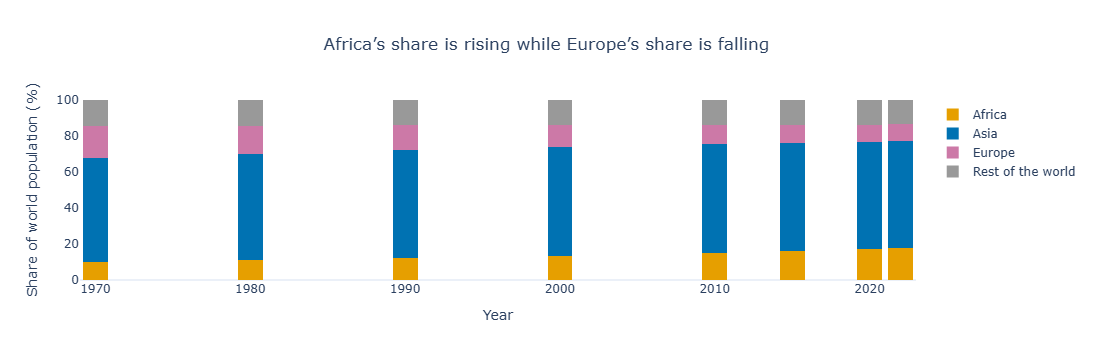

In [13]:

# Q7: Whose share of the world is rising?

# Calculate the population of each continent for every year
shares = df_long.groupby(
    ['Continent', 'Year']
)['Population'].sum().reset_index()

# Group the other continents together
shares['Group'] = shares['Continent'].replace({
    'North America': 'Rest of the world',
    'South America': 'Rest of the world',
    'Oceania': 'Rest of the world'
})

# Add together the population of the grouped continents
shares = shares.groupby(
    ['Group', 'Year']
)['Population'].sum().reset_index()

# Calculate each group's percentage of world population
world_total = shares.groupby('Year')['Population'].transform('sum')
shares['Share (%)'] = shares['Population'] / world_total * 100

# Choose colours for each group
colors = {
    'Africa': '#E69F00',
    'Asia': '#0072B2',
    'Europe': '#CC79A7',
    'Rest of the world': '#999999'
}

# Create a 100% stacked bar chart
fig = px.bar(
    shares,
    x='Year',
    y='Share (%)',
    color='Group',
    barmode='stack',
    color_discrete_map=colors,
    title='Africa’s share is rising while Europe’s share is falling',
    labels={
        'Year': 'Year',
        'Share (%)': 'Share of world population (%)',
        'Group': 'Continent'
    }
)

# Improve the chart appearance
fig.update_layout(
    template='plotly_white',
    title_x=0.5,
    yaxis_range=[0, 100],
    xaxis_showgrid=False,
    yaxis_showgrid=False,
    legend_title_text=''
)

fig.update_traces(
    marker_line_width=0
)

fig.show()
